# Xenium mouse brain: shape test along the distance to the dentate gyrus

Wildtype vs. TgCRND8, one section per condition, 347 genes. For every gene, does its expression change differently with the distance to the dentate gyrus in the two sections?

1. Quick pre-processing
2. The anchor and the distance to it (Fig. 1 of the poster)
3. The fit: parallel-curves test on single cells, full-rank ADVI, 12 worker processes
4. Results: diagnostics, volcano, p-value histogram, curves of the top gene

There are no slide effects (and so no empirical Bayes): they need at least 3 slides and this dataset has two sections. The test therefore compares section against section, and whether a difference is due to the condition is left to interpretation. With as many cells as here, only `tau` keeps negligible differences from becoming significant.

In [1]:
# One BLAS thread per process: the fits run in worker processes, and oversubscribed BLAS threads slow them down a lot.
# This has to happen before numpy is imported, so restart the kernel if numpy is already loaded.
import os

for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[var] = "1"

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import spatialdata as sd
import spatialdata_plot  # noqa: F401  (registers the `.pl` accessor)
import squidpy as sq
from matplotlib.colors import Normalize
from spatialdata.models import ShapesModel
from spatialdata.transformations import Identity

import diffsvg as dvg

/ictstr01/groups/ml01/workspace/laurens.lehner/tools/apps/miniforge/envs/pymc_env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Settings

* `LAYER`: log1p of the library-normalised counts, unscaled. `tau` is defined on this scale; `sc.pp.scale` would give it a different meaning for every gene.
* `TAU`: the smallest shape difference that counts for the test, in slope-equivalent units. 0.1 means the fold change between the conditions drifts by about 10% across the distance range.
* `GENES`: `None` fits all genes. See the note in the fit section about a trial run.

In [2]:
# On the cluster, xenium_advi.sbatch sets both paths.
DATA_PATH = os.environ.get("DIFFSVG_DATA", "/home/lehnerl/Arbeit/data/HiWi/both_conditions_5_7_without_noise.h5ad")
RESULTS_PATH = os.environ.get("DIFFSVG_RESULTS", "/home/lehnerl/Arbeit/data/HiWi/both_conditions_5_7_advi_results.pkl")
LAYER = "log1p_norm"
TAU = 0.1
N_WORKERS = 12
GENES = None

## 1. Pre-processing

Cells with fewer than 10 transcripts are dropped before anything else, so they cannot set a section's farthest distance. `.X` keeps the counts.

In [3]:
adata = sc.read_h5ad(DATA_PATH)
n_before = adata.obs["condition"].value_counts()
sc.pp.filter_cells(adata, min_counts=10)

adata.layers[LAYER] = adata.X.copy()
sc.pp.normalize_total(adata, layer=LAYER)
sc.pp.log1p(adata, layer=LAYER)

pd.DataFrame({"cells before": n_before, "cells after": adata.obs["condition"].value_counts()})

,cells before,cells after
condition,,
wildtype,58543,58523
TgCRND8,58439,58204


## 2. Anchor and distance

`var_by_distance` gives every cell its distance to the closest dentate gyrus cell of its own section, then scales each section to 0-1 by its own range. Both conditions therefore cover the whole x-axis, without blank space at the far end. The price is that the same physical distance gets a slightly different x in the two sections; the table shows by how much. The anchor cells themselves have no distance (`NaN`) and are not fitted.

In [4]:
sq.tl.var_by_distance(adata, cluster_key="Dentate_Gyrus", groups="anchor", library_key="condition", covariates="condition")
design = adata.obsm["design_matrix"]

raw_max = design.groupby("condition", observed=True)["anchor_raw"].max()
print(f"Farthest distance differs by {100 * (raw_max.max() / raw_max.min() - 1):.1f}% between the sections")
design.groupby("condition", observed=True).agg(
    fitted_cells=("anchor", "count"), anchor_cells=("anchor", lambda x: x.isna().sum()), farthest_cell=("anchor_raw", "max")
)

Farthest distance differs by 1.7% between the sections


,fitted_cells,anchor_cells,farthest_cell
condition,,,
TgCRND8,56500,1704,4028.298075
wildtype,56783,1740,3962.477884


Every cell is drawn as a circle of its own area, the anchor in red, all others by their scaled distance. Both panels share one colour scale.

Keep `method="matplotlib"`: with `method="datashader"` the overlapping circles of dense tissue come out unfilled, so the pyramidal layer around the anchor looks like an empty gap.

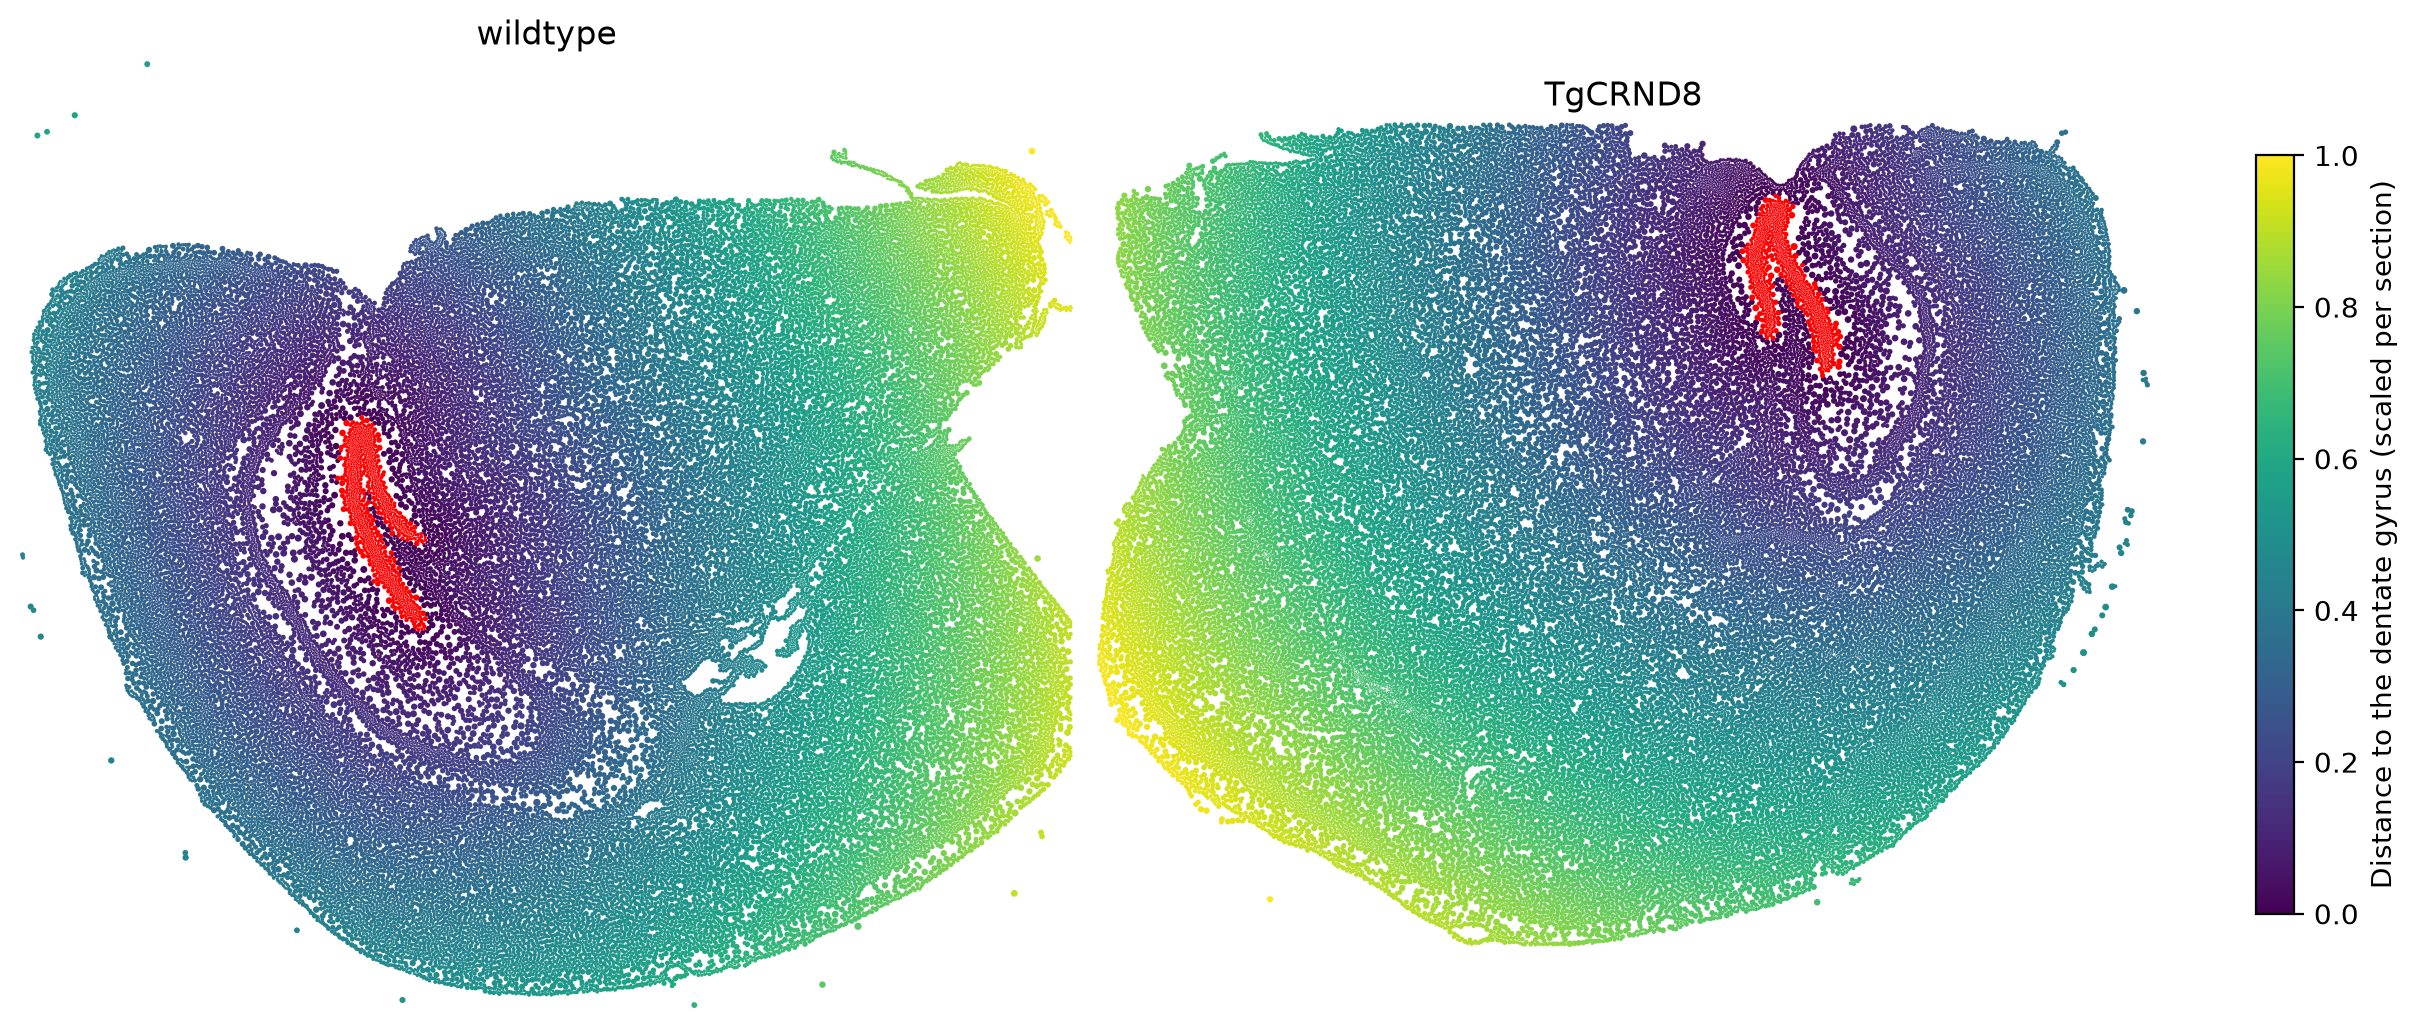

In [5]:
CONDITIONS = ["wildtype", "TgCRND8"]
is_anchor = (adata.obs["Dentate_Gyrus"] == "anchor").to_numpy()
distance = design["anchor"].to_numpy()
radius = np.sqrt(adata.obs["cell_area"].to_numpy() / np.pi)


def cell_shapes(mask, condition):
    """The cells in `mask` as circles, in the coordinate system of their section."""
    shapes = ShapesModel.parse(
        adata.obsm["spatial"][mask],
        geometry=0,
        radius=radius[mask],
        index=adata.obs_names[mask],
        transformations={condition: Identity()},
    )
    shapes["distance"] = distance[mask]
    return shapes


shapes = {}
for condition in CONDITIONS:
    in_section = (adata.obs["condition"] == condition).to_numpy()
    shapes[f"other_{condition}"] = cell_shapes(in_section & ~is_anchor, condition)
    shapes[f"anchor_{condition}"] = cell_shapes(in_section & is_anchor, condition)
sdata = sd.SpatialData(shapes=shapes)

norm = Normalize(0, 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), dpi=200, constrained_layout=True)
for ax, condition in zip(axes, CONDITIONS, strict=True):
    (
        sdata.pl.render_shapes(
            f"other_{condition}", color="distance", cmap="viridis", norm=norm, method="matplotlib", colorbar=False
        )
        .pl.render_shapes(f"anchor_{condition}", color="red", method="matplotlib")
        .pl.show(coordinate_systems=condition, ax=ax, title="", frameon=False)
    )
    ax.set_title(condition)
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="viridis"), ax=axes, shrink=0.7, label="Distance to the dentate gyrus (scaled per section)");

## 3. Fit

* **Model:** one spline per gene and condition, fitted to every non-anchor cell (`use_binned=False`), about 113,000 per gene. `bin_obs` only provides the spline basis and the prediction grid here.
* **Inference:** full-rank ADVI, started at the Laplace approximation and polished with Adam (`inference="advi"`).
* **Test:** `test="parallel"`, whether the two curves differ by more than a shift in level.

**Runtime:** the runtime and memory use on this many cells have not been measured. For a trial, set `GENES = list(adata.var_names[:12])` in the settings; the p-value is per gene, so results for a subset are valid too.

In [6]:
dvg.pp.bin_obs(adata, anchor="anchor", condition="condition", genes=GENES, layer=LAYER, n_bins=50, window_radius=None)
setup = dvg.tl.setup_model(adata)

t0 = time.perf_counter()
dvg.tl.fit_model(
    adata, setup, n_workers=N_WORKERS, use_binned=False, inference="advi", test="parallel", tau=TAU
)  # fmt: skip
elapsed = time.perf_counter() - t0
print(f"{elapsed / 60:.1f} min, {elapsed * N_WORKERS / len(setup.binned.genes):.0f} s per gene on one worker")

Fitting DiffSVG models:   0%|          | 0/347 [00:00<?, ?it/s]

Fitting DiffSVG models:   0%|          | 1/347 [02:28<14:16:55, 148.60s/it]

Fitting DiffSVG models:   1%|          | 2/347 [02:39<6:29:15, 67.70s/it]  

Fitting DiffSVG models:   1%|          | 3/347 [02:40<3:31:46, 36.94s/it]

Fitting DiffSVG models:   1%|          | 4/347 [02:40<2:08:07, 22.41s/it]

Fitting DiffSVG models:   1%|▏         | 5/347 [02:40<1:22:55, 14.55s/it]

... (322 outputs left out)

Fitting DiffSVG models: 100%|██████████| 347/347 [19:28<00:00,  2.18s/it]

Fitting DiffSVG models: 100%|██████████| 347/347 [19:28<00:00,  3.37s/it]

19.5 min, 40 s per gene on one worker



/tmp/ipykernel_2219094/274380629.py:5: UserWarning: 4 of 347 genes fail the variational diagnostics (expected: vi_khat < 0.7 and vi_ess > 0.5), so the approximation does not match the posterior for them: do not read their p-values.
  dvg.tl.fit_model(


The fit took long, so its tables are saved right away. Pre-processing plus this file is enough to continue later, for example with the clustering or the poster figures: put each table back with `adata.varm[key] = table` (the genes follow `adata.var_names`).

In [7]:
RESULT_KEYS = [key for key in adata.varm if key.startswith("dsvg_")]
pd.to_pickle({key: pd.DataFrame(adata.varm[key]) for key in RESULT_KEYS}, RESULTS_PATH)
RESULT_KEYS

['dsvg_stats',
 'dsvg_preds',
 'dsvg_curves_cond0_mean',
 'dsvg_curves_cond0_ci_low',
 'dsvg_curves_cond0_ci_high',
 'dsvg_curves_cond1_mean',
 'dsvg_curves_cond1_ci_low',
 'dsvg_curves_cond1_ci_high']

## 4. Results

### Did the approximation work?

`vi_khat` and `vi_ess` compare each gene's approximation with its true posterior. The covariance the test is built on can be trusted for `vi_khat < 0.7` and `vi_ess > 0.5`; do not read the p-values of genes that fail.

In [8]:
stats = adata.varm["dsvg_stats"].dropna(how="all").copy()
stats["vi_trusted"] = (stats["vi_khat"] < 0.7) & (stats["vi_ess"] > 0.5)

print(f"{stats['vi_trusted'].sum()} of {len(stats)} genes pass the variational diagnostics")
print(f"p < 0.05: {(stats['parallel_pval'] < 0.05).sum()}, BH-adjusted < 0.05: {(stats['parallel_pval_adj'] < 0.05).sum()}")
stats.loc[~stats["vi_trusted"], ["vi_khat", "vi_ess", "parallel_pval"]]

343 of 347 genes pass the variational diagnostics
p < 0.05: 152, BH-adjusted < 0.05: 149


,vi_khat,vi_ess,parallel_pval
Cd69,0.189406,0.444427,1.0
Itgax,0.305209,0.397640,1.0
Slc6a3,0.152027,0.470670,1.0
Tnf,0.576669,0.140112,1.0


### Ranked genes

Ordered by p-value, with ties (p-values that underflow to 0) broken by the larger statistic.

In [9]:
ranked = stats.sort_values(["parallel_pval", "parallel_stat"], ascending=[True, False])
columns = ["shape_diff", "slope_diff", "slope_diff_ci_low", "slope_diff_ci_high", "parallel_stat", "parallel_pval", "parallel_pval_adj", "integral", "vi_khat", "vi_ess", "vi_trusted"]
ranked[columns].head(25)

,shape_diff,slope_diff,slope_diff_ci_low,slope_diff_ci_high,parallel_stat,parallel_pval,parallel_pval_adj,integral,vi_khat,vi_ess,vi_trusted
Arc,1.037507,-0.780495,-0.819637,-0.742702,5471.070230,0.000000e+00,0.000000e+00,-0.179332,0.150143,0.772780,True
Nwd2,0.545525,0.082161,0.057269,0.106117,2943.699569,0.000000e+00,0.000000e+00,0.005804,0.123817,0.753914,True
Dcn,0.907573,0.436080,0.414722,0.456656,2574.782491,0.000000e+00,0.000000e+00,0.109587,0.125837,0.746833,True
Nrn1,1.321929,-0.551339,-0.606874,-0.497912,2545.736662,0.000000e+00,0.000000e+00,-0.090695,0.192786,0.786841,True
Nr2f2,0.579615,0.271913,0.236458,0.306241,2481.466213,0.000000e+00,0.000000e+00,0.211758,0.121320,0.768771,True
Nrp2,0.539911,-0.122976,-0.148037,-0.098856,2409.741161,0.000000e+00,0.000000e+00,-0.027098,0.123774,0.754206,True
Igf2,0.710476,-0.108831,-0.142834,-0.075916,2405.178136,0.000000e+00,0.000000e+00,0.065589,0.123309,0.767056,True
Cabp7,0.550063,-0.462347,-0.496016,-0.429762,2257.341520,0.000000e+00,0.000000e+00,0.111969,0.118870,0.766642,True
Mbp,1.290632,-1.001799,-1.066696,-0.939303,2040.257969,0.000000e+00,0.000000e+00,0.019072,0.232762,0.793357,True
Cpne4,0.623343,-0.084078,-0.118856,-0.050405,1988.510260,0.000000e+00,0.000000e+00,0.024227,0.126900,0.767984,True


### Volcano and p-value histogram

The curves are compared as condition 1 minus condition 0, with the condition labels in sorted order, so **`TgCRND8` is condition 0 and `wildtype` is condition 1**. A positive `slope_diff` means wildtype minus TgCRND8 rises with the distance; the cell prints the coding of this run.

With `tau > 0`, genes whose shape difference is clearly below `tau` get p-values near 1, so the histogram has a second peak there by design.

{'0': 'TgCRND8', '1': 'wildtype'}


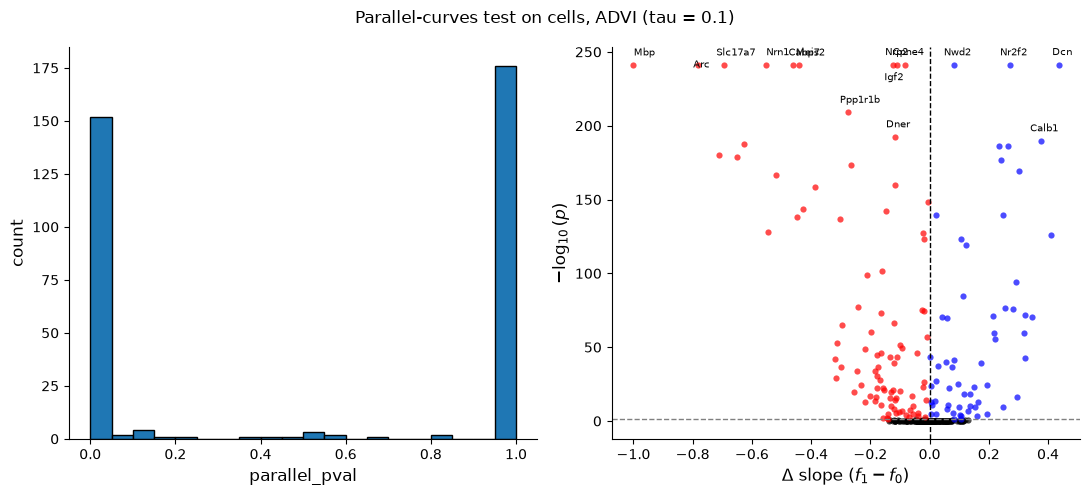

In [10]:
print(adata.uns["dsvg_curves_condition_categories"])

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
dvg.pl.plot_pvalue_histogram(stats, ax=axes[0])
dvg.pl.plot_volcano(stats, ax=axes[1], n_label=15)
fig.suptitle(f"Parallel-curves test on cells, ADVI (tau = {TAU})")
fig.tight_layout();

### Curves of the top gene

The top gene that passes the diagnostics, by condition. The bands are quantiles of the posterior-predictive draws, which include the noise of a single cell, so on a fit to cells they are much wider than the uncertainty of the curve itself. Judge the shape difference by the test and the mean curves, not by whether the bands overlap.

Arc


<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W

:Overlay
   .Area.I         :Area   [distance]   (smoothed expression,expression_upper)
   .Curve.TgCRND8  :Curve   [distance]   (smoothed expression)
   .Area.II        :Area   [distance]   (smoothed expression,expression_upper)
   .Curve.Wildtype :Curve   [distance]   (smoothed expression)
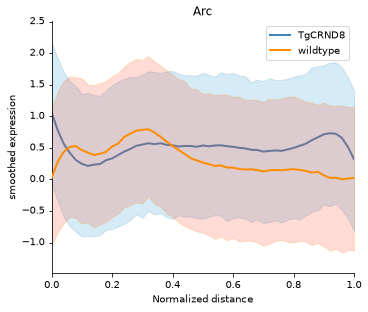

In [11]:
TOP_GENE = ranked.index[ranked["vi_trusted"]][0]
print(TOP_GENE)
dvg.pl.plot_prediction_curve(adata, gene=TOP_GENE)